<a href="https://colab.research.google.com/github/joicemena8-spec/Customer-Churn-Intelligence-and-Retention-System-Project/blob/Visualization/OurProject_with_DT%26RF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub, os
from scipy import stats


path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset")
print(os.listdir(path))

Using Colab cache for faster access to the 'telco-customer-churn-ibm-dataset' dataset.
['Telco_customer_churn.xlsx']


In [ ]:
df = pd.read_excel(os.path.join(path, "Telco_customer_churn.xlsx"))
df_clean = df.copy()

Understanding Data

In [ ]:
df.shape

(7043, 33)

In [ ]:
df.head(5)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Fixing Data Types

In [ ]:
df.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

In [ ]:
df.dtypes

,0
CustomerID,object
Count,int64
Country,object
State,object
City,object
Zip Code,int64
Lat Long,object
Latitude,float64
Longitude,float64
Gender,object


In [ ]:
text_cols = df.select_dtypes(include='object').columns

# NOTE: 'Total Charges' is a MIXED column: 7032 numbers + 11 ' ' (space) blanks.
# Calling .str.strip() on it returns NaN for every numeric entry, which wipes the
# whole column and makes every Total Charges plot flat at 0 after fillna(0).
# So: skip it in the loop, cast to string first, then strip, then convert.
for col in text_cols:
    if col == 'Total Charges':
        continue
    df[col] = df[col].str.strip()

df['Total Charges'] = pd.to_numeric(
    df['Total Charges'].astype(str).str.strip(),
    errors='coerce'
)


In [ ]:
df['Total Charges'].dtype

dtype('float64')

In [ ]:
df['Total Charges'].isnull().sum()  # now 11: only the 11 space-blank rows


np.int64(11)

Data Validation

In [ ]:
print("Negative Monthly Charges:",
      (df['Monthly Charges'] < 0).sum())

print("Negative Total Charges:",
      (df['Total Charges'] < 0).sum())

print("Invalid Tenure:",
      (~df['Tenure Months'].between(0, 72)).sum())

print("Invalid Churn Values:",
      (~df['Churn Value'].isin([0, 1])).sum())

Negative Monthly Charges: 0
Negative Total Charges: 0
Invalid Tenure: 0
Invalid Churn Values: 0


Missing Values

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0]
missing

,0
Total Charges,11
Churn Reason,5174


In [ ]:
df['Total Charges'] = df['Total Charges'].fillna(0)
df['Churn Reason'] = df['Churn Reason'].fillna('Not Churned')

Handling dublicats

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['CustomerID'].duplicated().sum()

np.int64(0)

In [ ]:
df['CustomerID'].nunique()

7043

Fixing Values and Text in Columns

In [ ]:
cols = df.columns.tolist()
for col in cols:
    print(col, ':', df[col].unique())

CustomerID : ['3668-QPYBK' '9237-HQITU' '9305-CDSKC' ... '2234-XADUH' '4801-JZAZL'
 '3186-AJIEK']
Count : [1]
Country : ['United States']
State : ['California']
City : ['Los Angeles' 'Beverly Hills' 'Huntington Park' ... 'Standish' 'Tulelake'
 'Olympic Valley']
Zip Code : [90003 90005 90006 ... 96128 96134 96146]
Lat Long : ['33.964131, -118.272783' '34.059281, -118.30742' '34.048013, -118.293953'
 ... '40.346634, -120.386422' '41.813521, -121.492666'
 '39.191797, -120.212401']
Latitude : [33.964131 34.059281 34.048013 ... 40.346634 41.813521 39.191797]
Longitude : [-118.272783 -118.30742  -118.293953 ... -120.386422 -121.492666
 -120.212401]
Gender : ['Male' 'Female']
Senior Citizen : ['No' 'Yes']
Partner : ['No' 'Yes']
Dependents : ['No' 'Yes']
Tenure Months : [ 2  8 28 49 10  1 47 17  5 34 11 15 18  9  7 12 25 68 55 37  3 27 20  4
 58 53 13  6 19 59 16 52 24 32 38 54 43 63 21 69 22 61 60 48 40 23 39 35
 56 65 33 30 45 46 62 70 50 44 71 26 14 41 66 64 29 42 67 51 31 57 36 72
  0]
Pho

Outliers

In [ ]:
outlier_cols = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(f'{col}: {len(outliers)} outliers')

Tenure Months: 0 outliers
Monthly Charges: 0 outliers
Total Charges: 0 outliers
CLTV: 0 outliers


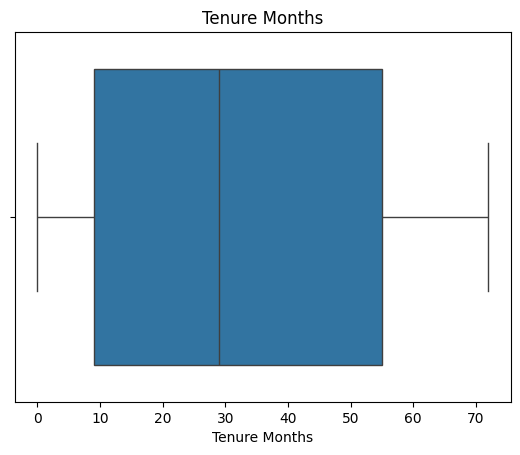

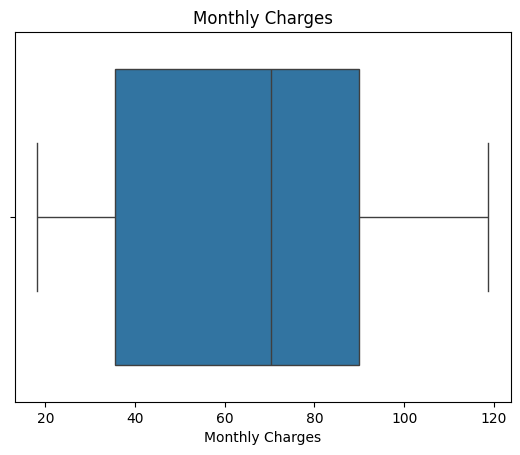

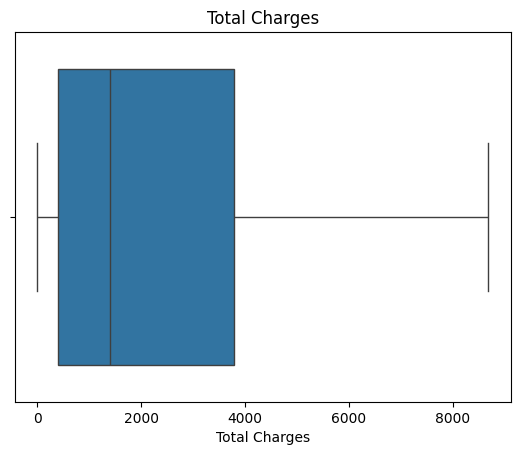

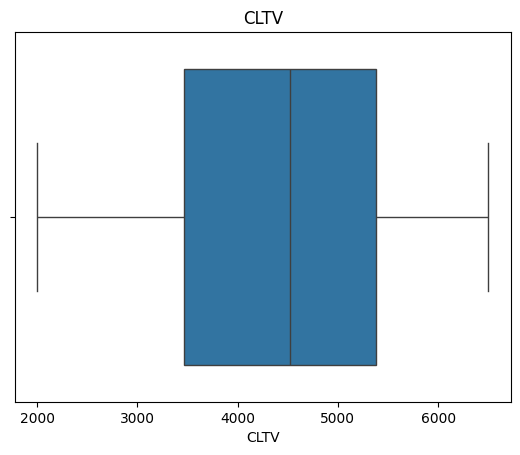

In [ ]:
for col in outlier_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

Final check

In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Customer IDs:")
print(df['CustomerID'].duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nTarget Distribution:")
print(df['Churn Value'].value_counts(normalize=True))

Dataset Shape: (7043, 33)

Missing Values:
0

Duplicate Rows:
0

Duplicate Customer IDs:
0

Data Types:
CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Label           object
Churn Value            int64
Churn Score            int

SQL Analysis & Business Questions

In [ ]:
import sqlite3

conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

def run(query, quiet=False):
    cursor.execute(query)
    conn.commit()
    if not quiet:
        return cursor.fetchall()

In [ ]:
import sqlite3
conn = sqlite3.connect('telco_churn.db')
cursor = conn.cursor()
df.to_sql('telco_customers', conn, if_exists='replace', index=False)

7043

1. What is the overall percentage of customers who churned compared to the total number of customers?

In [ ]:
query = """SELECT
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers;"""

pd.read_sql_query(query, conn)

,total_customers,churned_customers,churn_rate_percentage
0,7043,1869,26.54


2. How does the churn rate vary across different contract types?

In [ ]:
query = """SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY Contract
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn)

,Contract,total_customers,churned_customers,churn_rate_percentage
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


3. What is the average monthly charge for churned customers compared to retained customers?

In [ ]:
query = """SELECT
    "Churn Label",
    ROUND(AVG("Monthly Charges"), 2) AS avg_monthly_charges
FROM telco_customers
GROUP BY "Churn Label";"""

pd.read_sql_query(query, conn)

,Churn Label,avg_monthly_charges
0,No,61.27
1,Yes,74.44


4. What are the top 5 most common reasons for customer churn?

In [ ]:
query = """SELECT
    "Churn Reason",
    COUNT(*) AS count
FROM telco_customers
WHERE "Churn Value" = 1
GROUP BY "Churn Reason"
ORDER BY count DESC
LIMIT 5;"""

pd.read_sql_query(query, conn)

,Churn Reason,count
0,Attitude of support person,192
1,Competitor offered higher download speeds,189
2,Competitor offered more data,162
3,Don't know,154
4,Competitor made better offer,140


5. Which internet service type has the highest customer churn rate?

In [ ]:
query = """SELECT
    "Internet Service",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Internet Service"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn)

,Internet Service,total_customers,churned_customers,churn_rate_percentage
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


6. How does the churn rate differ across various payment methods?

In [ ]:
query = """SELECT
    "Payment Method",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Payment Method"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn)

,Payment Method,total_customers,churned_customers,churn_rate_percentage
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


7. What is the churn rate among senior citizens compared to non-senior citizens?

In [ ]:
query = """SELECT
    "Senior Citizen",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Senior Citizen";"""

pd.read_sql_query(query, conn)

,Senior Citizen,total_customers,churned_customers,churn_rate_percentage
0,No,5901,1393,23.61
1,Yes,1142,476,41.68


8. What is the average tenure (in months) of customers who churned?

In [ ]:
query = """SELECT
    ROUND(AVG("Tenure Months"), 2) AS avg_tenure_months
FROM telco_customers
WHERE "Churn Value" = 1;"""

pd.read_sql_query(query, conn)

,avg_tenure_months
0,17.98


9. Who are the high-paying customers (monthly charges > 80) that churned, and what are their payment methods?

In [ ]:
query = """SELECT
    CustomerID,
    "Monthly Charges",
    "Tenure Months",
    "Payment Method"
FROM telco_customers
WHERE "Churn Value" = 1
  AND "Monthly Charges" > 80
ORDER BY "Monthly Charges" DESC;"""

pd.read_sql_query(query, conn)

,CustomerID,Monthly Charges,Tenure Months,Payment Method
0,8199-ZLLSA,118.35,67,Bank transfer (automatic)
1,2889-FPWRM,117.80,72,Bank transfer (automatic)
2,2302-ANTDP,117.45,48,Electronic check
3,9053-JZFKV,116.20,67,Credit card (automatic)
4,1444-VVSGW,115.65,70,Credit card (automatic)
...,...,...,...,...
901,7693-LCKZL,80.15,5,Electronic check
902,6204-IEUXJ,80.10,3,Credit card (automatic)
903,4277-PVRAN,80.10,8,Bank transfer (automatic)
904,4547-KQRTM,80.05,10,Bank transfer (automatic)


10. How does having online security impact the customer churn rate?

In [ ]:
query = """SELECT
    "Online Security",
    COUNT(*) AS total_customers,
    SUM("Churn Value") AS churned_customers,
    ROUND(SUM("Churn Value") * 100.0 / COUNT(*), 2) AS churn_rate_percentage
FROM telco_customers
GROUP BY "Online Security"
ORDER BY churn_rate_percentage DESC;"""

pd.read_sql_query(query, conn)

,Online Security,total_customers,churned_customers,churn_rate_percentage
0,No,3498,1461,41.77
1,Yes,2019,295,14.61
2,No internet service,1526,113,7.40


## Exploratory Data Analysis (EDA)

Univariate and bivariate analysis to understand churn drivers.


### 1. Univariate Analysis - Numeric Features

Distribution shapes of key numeric customer metrics.


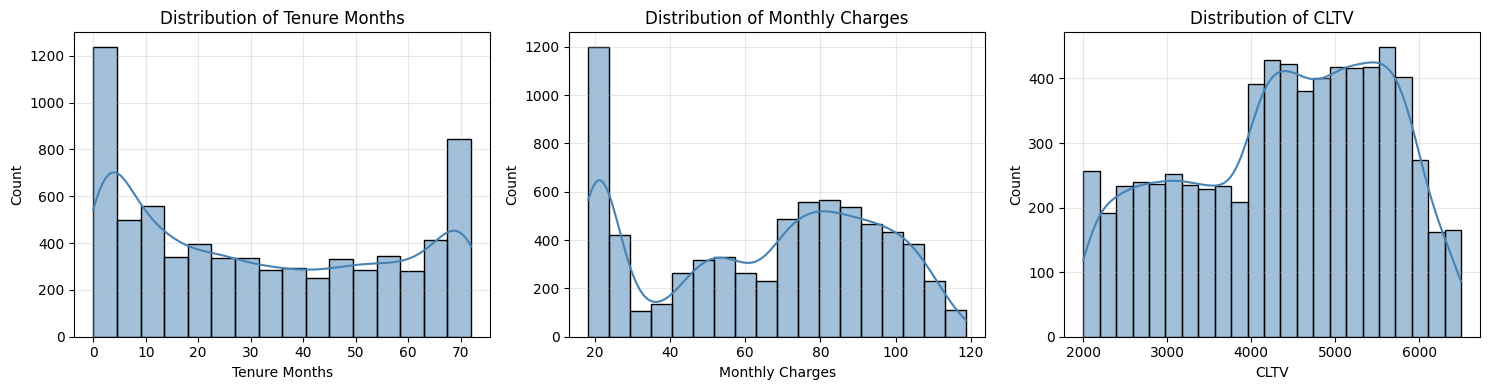

In [ ]:
numeric_cols = ['Tenure Months', 'Monthly Charges', 'CLTV']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col].dropna(), ax=axes[i], kde=True, color='steelblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

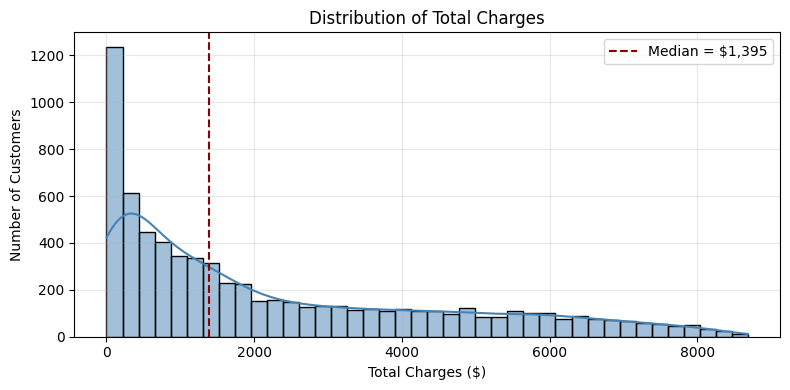

In [ ]:
# 'Total Charges' is numeric again after the dtype fix, so it can be plotted like the rest
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df['Total Charges'].dropna(), bins=40, kde=True, color='steelblue', ax=ax)

median_tc = df['Total Charges'].median()
ax.axvline(median_tc, color='darkred', linestyle='--', linewidth=1.5,
           label=f'Median = ${median_tc:,.0f}')

ax.set_title('Distribution of Total Charges')
ax.set_xlabel('Total Charges ($)')
ax.set_ylabel('Number of Customers')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Key Insights from Numeric Feature Distributions

1. **Tenure Months (Bimodal — New Customers vs Long-Term Loyalists)**
   * **Observation:** **1,371 customers (19.5%)** are in their first six months (`0–5`), and a second peak of **671 customers (9.5%)** sits at `66–72` months; the middle is a flat plateau of about 5–6% per 6-month bin. Median tenure is **29 months** (mean **32.4**).
   * **What It Means:** The base is split into a large "new and undecided" cohort and a stable "locked-in" cohort. Churn falls monotonically with tenure: **49.8%** churn in the first 9 months versus **7.7%** after 55 months.
   * **Suggested Action:** Treat the first 6 months as the retention-critical window (onboarding calls, first-bill support, early loyalty offer) — **41.9%** of all churn happens there, and customers under 6 months still churn at **52.9%**.

2. **Monthly Charges (Bimodal Pricing Structure)**
   * **Observation:** **1,389 customers (19.7%)** pay `$18–$25`, a trough exists at `$30–$40` (**184 customers, 2.6%**), and a second, wider peak spans `$70–$100` (**2,683 customers, 38.1%**). Median is
    **$70.35**, mean **$64.76**.
   * **What It Means:** The base contains two product worlds: cheap phone-only / DSL lines and bundled fiber / high-tier plans. Churn rises with the price tier (**11.2%** in the lowest quartile → **37.5%** in the `$70–$90` quartile), so the expensive tier is both the revenue engine and the churn engine.
   * **Suggested Action:** Leave the low tier alone (it barely churns) and spend retention budget on the **$70+** tier: service-quality checks, annual price locks and bundle upgrades instead of blanket discounts.

3. **Total Charges (Strong Right Skew — Cumulative Spend)**
   * **Observation:** The distribution is heavily right-skewed (skew **0.96**): **2,011 customers (28.6%)** have paid less than `$500` in total, the median is **$1,394.55**, the mean is
    **$2,279.73**, and the tail reaches **$8,684.80**. The small spike at `0` is the **11 brand-new customers** (`Tenure Months = 0`).
   * **What It Means:** `Total Charges ≈ Tenure × Monthly Charges`, so the tall left side of the histogram is simply "new customers" and the long tail is "old, high-value customers". Churn falls along it (**43.2%** under `$399` → **14.5%** above `$3,787`), which repeats the tenure signal rather than adding a new one.
   * **Suggested Action:** Use `Total Charges` as a loyalty / value proxy for prioritisation (high-total customers are the cheapest to keep), but do not present it as an independent churn driver — see the correlation section.

4. **CLTV (Wide, Almost Uniform — Weak Churn Signal)**
   * **Observation:** `CLTV` is spread almost evenly between **2,003 and 6,500** (median **4,527**, mean **4,400**, skew **-0.31**), with a visible drop above `6,000` (only **425 customers, 6.0%**).
   * **What It Means:** The base is not concentrated in a few value classes, and churn moves only mildly with value (**34.4%** in the lowest CLTV quartile → **20.7%** in the highest).
   * **Suggested Action:** Use CLTV as a *weighting* variable (`P(churn) × CLTV` = expected revenue at risk) rather than as a standalone predictor.

---

### 2. Univariate Analysis - Categorical Features

Frequency of key categorical attributes. This shows how customers are distributed across segments, without computing churn rates.


/tmp/ipykernel_31200/3990802125.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_31200/3990802125.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_31200/3990802125.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_31200/3990802125.py:6: Fu

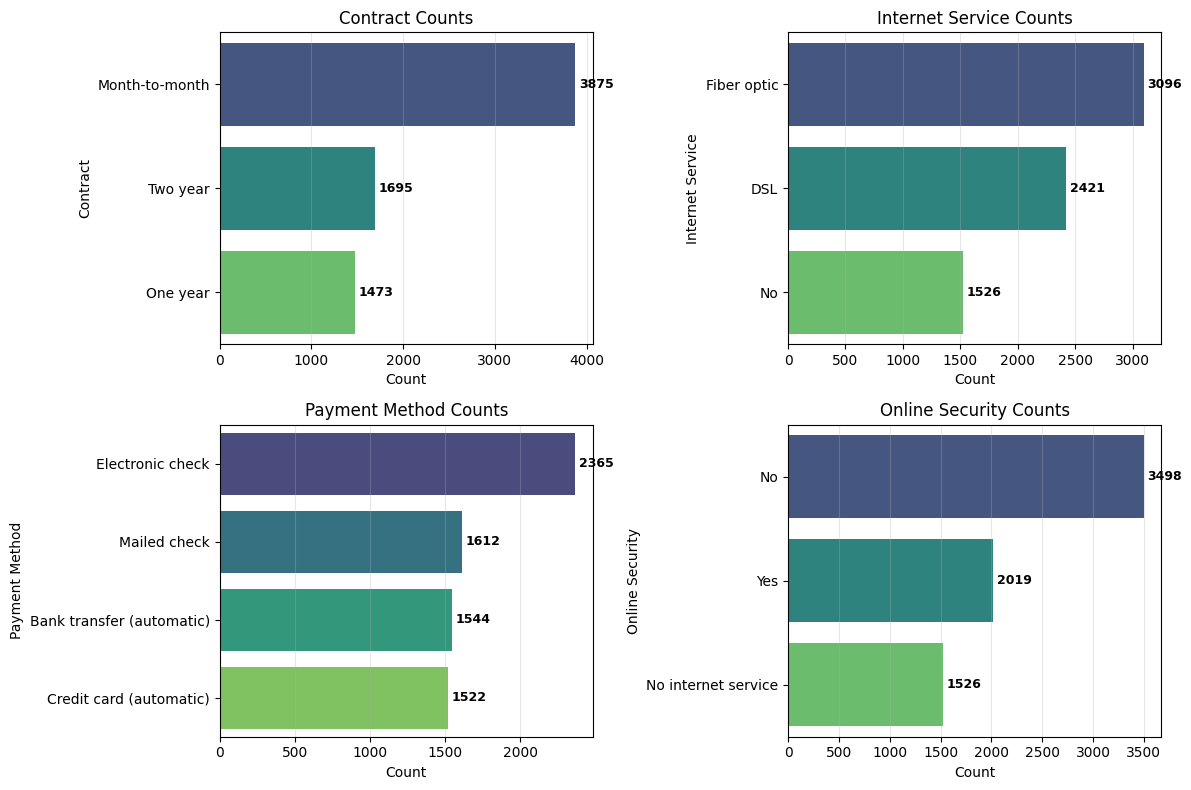

In [ ]:
cat_cols_part1 = ['Contract', 'Internet Service', 'Payment Method', 'Online Security']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for i, col in enumerate(cat_cols_part1):
    sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
    axes[i].set_title(f'{col} Counts')
    axes[i].set_xlabel('Count')
    axes[i].grid(True, alpha=0.3, axis='x')
    max_val = df[col].value_counts().max()
    for p in axes[i].patches:
        width = p.get_width()
        axes[i].text(width + max_val * 0.01, p.get_y() + p.get_height()/2,
                     f'{int(width)}', va='center', ha='left', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


/tmp/ipykernel_31200/2313507847.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_31200/2313507847.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
/tmp/ipykernel_31200/2313507847.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')


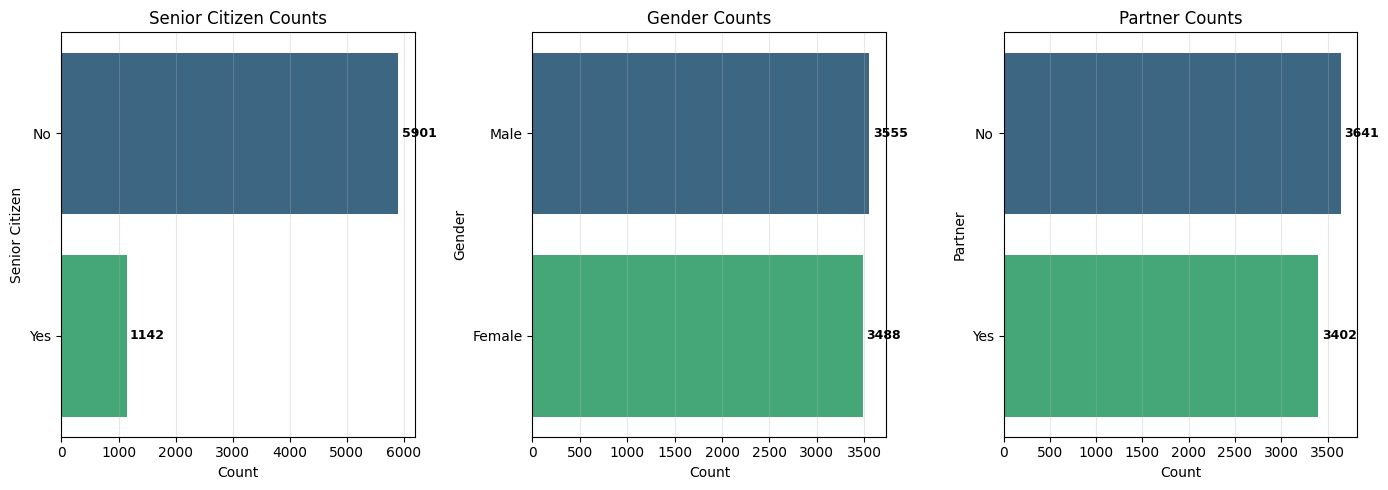

In [ ]:
cat_cols_part2 = ['Senior Citizen', 'Gender', 'Partner']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes = axes.flatten()
for i, col in enumerate(cat_cols_part2):
    sns.countplot(y=col, data=df, ax=axes[i], order=df[col].value_counts().index, palette='viridis')
    axes[i].set_title(f'{col} Counts')
    axes[i].set_xlabel('Count')
    axes[i].grid(True, alpha=0.3, axis='x')
    max_val = df[col].value_counts().max()
    for p in axes[i].patches:
        width = p.get_width()
        axes[i].text(width + max_val * 0.01, p.get_y() + p.get_height()/2,
                     f'{int(width)}', va='center', ha='left', fontsize=9, fontweight='bold')
for j in range(len(cat_cols_part2), len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.show()


### Key Insights from Categorical Feature Distributions

1. **Month-to-Month Contracts Are the Majority (55.0%)**
   * **Observation:** **3,875 customers (55.0%)** are on month-to-month contracts, versus **1,473 (20.9%)** one-year and **1,695 (24.1%)** two-year contracts.
   * **What It Means:** Over half of the base has no cancellation barrier, and that segment carries **42.7%** churn versus **11.3%** (one-year) and **2.8%** (two-year). Month-to-month customers account for **88.6%** of all churned customers.
   * **Suggested Action:** Convert month-to-month customers to annual plans with a targeted upgrade offer (e.g. one month free) instead of a blanket price cut.

2. **Fiber Optic Is the Largest and Riskiest Internet Segment**
   * **Observation:** **Fiber optic 3,096 (44.0%)**, **DSL 2,421 (34.4%)**, **No internet 1,526 (21.7%)**.
   * **What It Means:** The premium product churns the most (**41.9%** fiber vs **19.0%** DSL vs **7.4%** no internet) — a speed / price / reliability positioning problem, not a demand problem.
   * **Suggested Action:** Benchmark fiber speed and price against competitors (see the churn-reasons section) and pair fiber with free security / support add-ons.

3. **Manual Payment (Electronic Check) Dominates**
   * **Observation:** **Electronic check 2,365 (33.6%)**, **mailed check 1,612 (22.9%)**, **bank transfer 1,544 (21.9%)**, **credit card 1,522 (21.6%)** — i.e. **56.5%** pay manually.
   * **What It Means:** Electronic-check users churn at **45.3%**, more than 2.5× the automatic-payment groups (**16.7%** bank transfer, **15.2%** credit card). Manual billing adds friction without adding commitment.
   * **Suggested Action:** Offer a small recurring credit for switching to autopay, and keep `Payment Method` in the model as a risk feature.

4. **Add-On Gap: Nearly Half Have No Online Security**
   * **Observation:** **Online Security — No 3,498 (49.7%)**, **Yes 2,019 (28.7%)**, **No internet service 1,526 (21.7%)**.
   * **What It Means:** Among internet subscribers only, **63.4%** have no online security, and they churn at **41.8%** versus **14.6%** for protected ones. Tech Support shows the same pattern (**41.6%** vs **15.2%**).
   * **Suggested Action:** Bundle security and support into fiber plans — add-ons create switching friction, so they act as retention tools rather than pure upsell.

5. **Demographics Are Balanced — Except Senior Citizens**
   * **Observation:** **Non-senior 5,901 (83.8%)** vs **senior 1,142 (16.2%)**; **Male 3,555 (50.5%) / Female 3,488 (49.5%)**; **No partner 3,641 (51.7%) / Yes 3,402 (48.3%)**.
   * **What It Means:** Gender has essentially no relationship with churn (**26.2% vs 26.9%**, p = 0.49), while senior citizens churn at **41.7%** vs **23.6%** and customers without a partner at **33.0%** vs **19.7%**.
   * **Suggested Action:** Drop `Gender` from the model; build a phone-first, simplified-billing support track for senior customers and family / partner bundles for single-line households.

---

### 3. Bivariate Analysis - Numeric Features vs Churn Status

Boxplots comparing each numeric feature between churned and retained customers. This reveals whether a feature separates the two classes, which is directly relevant for classification models.


/tmp/ipykernel_31200/3055127357.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Value', y=col, data=df, ax=axes[row, col_idx], palette='Set2')
/tmp/ipykernel_31200/3055127357.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Value', y=col, data=df, ax=axes[row, col_idx], palette='Set2')
/tmp/ipykernel_31200/3055127357.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn Value', y=col, data=df, ax=axes[row, col_idx], palette='Set2')
/tmp/ipykernel_31200/3055127357.py:7: FutureWarning: 

Passing `palette` withou

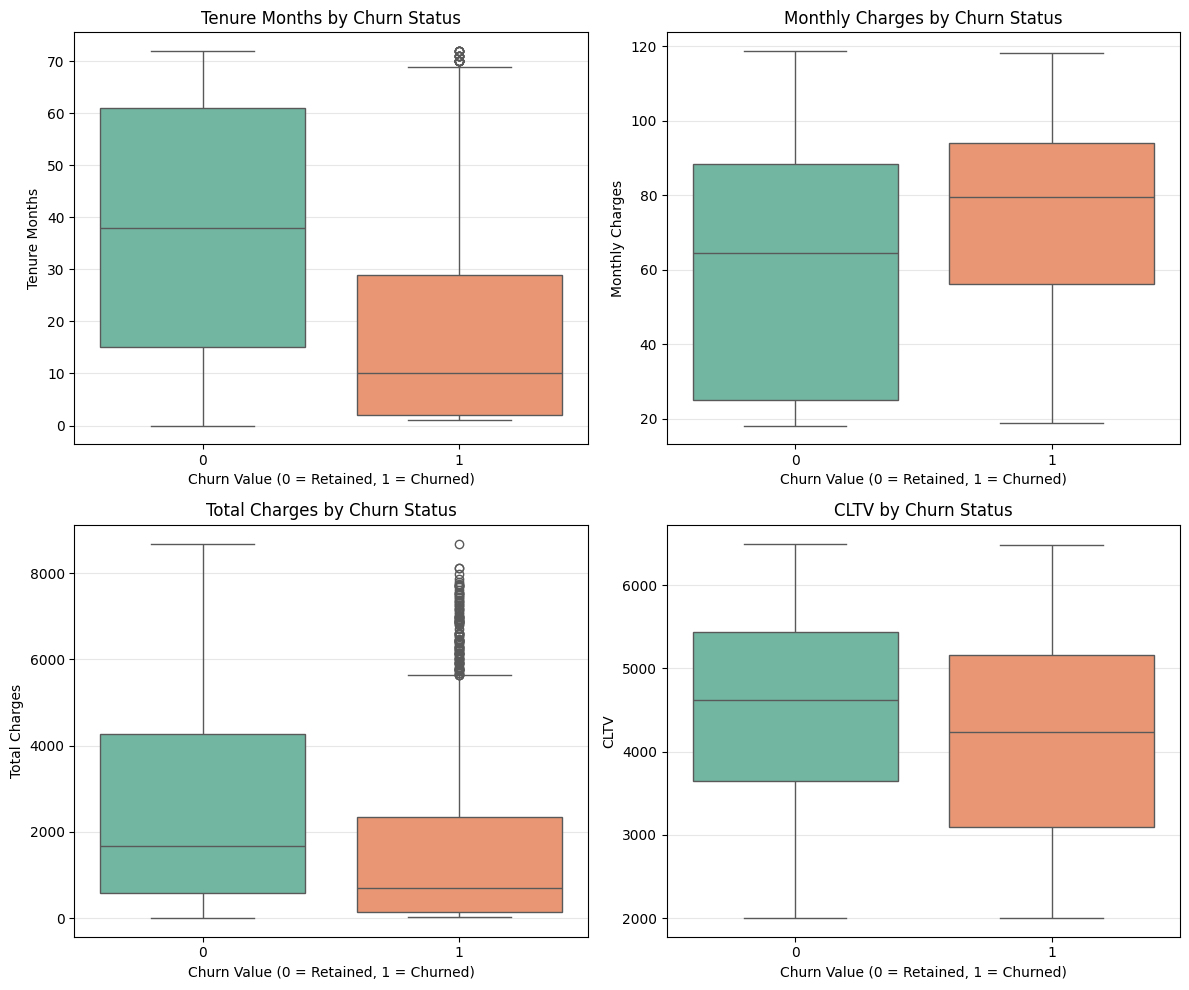

In [ ]:
numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, col in enumerate(numeric_cols):
    row = i // 2
    col_idx = i % 2
    sns.boxplot(x='Churn Value', y=col, data=df, ax=axes[row, col_idx], palette='Set2')
    axes[row, col_idx].set_title(f'{col} by Churn Status')
    axes[row, col_idx].set_xlabel('Churn Value (0 = Retained, 1 = Churned)')
    axes[row, col_idx].set_ylabel(col)
    axes[row, col_idx].grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


### Key Insights from Numeric Features vs Churn Status

1. **Tenure Months — The Clearest Separation**
   * **Observation:** Churned customers have a median tenure of **10 months** (Q1–Q3: **2–29**) versus **38 months** (Q1–Q3: **15–61**) for retained ones; the top of the churner box sits **below** the retained median.
   * **What It Means:** Churn is an early-life problem — **41.9%** of all churn happens in the first 6 months and 75% of churners leave within 29 months, so "has the customer survived the first year?" will be the most useful split in any model.
   * **Suggested Action:** Schedule retention interventions in months 1–12, not after the contract is already at risk.

2. **Monthly Charges — Churners Pay More**
   * **Observation:** Churned median **$79.65**
    versus retained **$64.43** (means 74.4 vs 61.3); even the churner lower quartile (**$56.15**)
    is far above the retained one (**$25.10**).
   * **What It Means:** Price level shifts the odds, but plenty of high payers stay and plenty of low payers leave — price alone is not a rule.
   * **Suggested Action:** Combine price with contract and tenure (high bill + month-to-month + under 12 months is the real hotspot).

3. **Total Charges — Separation Comes From Tenure, Not Spending**
   * **Observation:** Churned median
   **$703.55**
    versus retained **$1,679.53**, with heavy overlap on the low end and a very compressed churner box (**$135–$2,331**).
   * **What It Means:** `Total Charges` separates the classes only because it is cumulative — a churner stops paying early. It adds no information beyond tenure × monthly charges.
   * **Suggested Action:** Keep it for value reporting, but for Logistic Regression / SVM use tenure and monthly charges (or their product) and avoid feeding duplicate, collinear inputs.

4. **CLTV — Almost No Visual Separation**
   * **Observation:** Churned median **4,238** (Q1–Q3: 3,101–5,166) versus retained **4,620** (3,644–5,435) — the boxes almost completely overlap.
   * **What It Means:** High-value customers are not meaningfully less likely to leave; CLTV measures business value, not churn propensity.
   * **Suggested Action:** Do not expect CLTV to improve classification accuracy; use it downstream in the revenue-at-risk calculation.

---

### 4. Statistical Significance Tests

Hypothesis tests are to identify which features have a statistically significant relationship with churn.

- Categorical features: Chi-square test of independence.
- Numeric features: Mann-Whitney U test (non-parametric) comparing churned vs retained.


In [ ]:
print('=== Categorical Features vs Churn (Chi-square) ===')
cat_cols = ['Contract', 'Internet Service', 'Payment Method', 'Online Security', 'Senior Citizen', 'Gender', 'Partner']
for col in cat_cols:
    contingency = pd.crosstab(df[col], df['Churn Value'])
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    print(f'{col}: chi2={chi2:.3f}, p-value={p:.4f}', '*' if p < 0.05 else '')

print()
print('=== Numeric Features vs Churn (Mann-Whitney U) ===')
numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']
for col in numeric_cols:
    churned = df[df['Churn Value'] == 1][col].dropna()
    retained = df[df['Churn Value'] == 0][col].dropna()
    stat, p = stats.mannwhitneyu(churned, retained, alternative='two-sided')
    print(f'{col}: U={stat:.3f}, p-value={p:.4f}', '*' if p < 0.05 else '')


=== Categorical Features vs Churn (Chi-square) ===
Contract: chi2=1184.597, p-value=0.0000 *
Internet Service: chi2=732.310, p-value=0.0000 *
Payment Method: chi2=648.142, p-value=0.0000 *
Online Security: chi2=849.999, p-value=0.0000 *
Senior Citizen: chi2=159.426, p-value=0.0000 *
Gender: chi2=0.484, p-value=0.4866 
Partner: chi2=158.733, p-value=0.0000 *

=== Numeric Features vs Churn (Mann-Whitney U) ===
Tenure Months: U=2515538.000, p-value=0.0000 *
Monthly Charges: U=6003125.500, p-value=0.0000 *
Total Charges: U=3381224.000, p-value=0.0000 *
CLTV: U=4053479.500, p-value=0.0000 *


### Key Insights from the Significance Tests

1. **Every Categorical Feature Except Gender Is Significant**
   * **Observation:** Contract (χ² = **1,184.6**, p ≈ 5.9e-258, Cramér's V = **0.41**), Online Security (χ² = **850.0**, V = **0.35**), Internet Service (χ² = **732.3**, V = **0.32**), Payment Method (χ² = **648.1**, V = **0.30**), Partner (χ² = **158.7**, V = **0.15**), Senior Citizen (χ² = **159.4**, V = **0.15**) are all significant at α = 0.05, while **Gender (χ² = 0.48, p = 0.487)** is not.
   * **What It Means:** With n = 7,043 almost everything is "significant", so p-values alone are not useful for ranking. Effect size (Cramér's V) shows Contract (**0.41**) is about **1.4×** Payment Method (**0.30**) and roughly **50×** Gender (**0.008**).
   * **Suggested Action:** Drop `Gender` from the model and dashboard, and rank the remaining categorical features by V rather than by p.

2. **All Numeric Features Differ Between Churned and Retained (Mann-Whitney U)**
   * **Observation:** Tenure **U = 2,515,538**, p ≈ 2.4e-208 (medians **10** vs **38**); Total Charges **U = 3,381,224**, p ≈ 5.7e-83 (**$703.55** vs **$1,679.53**); Monthly Charges **U = 6,003,125.5**, p ≈ 3.3e-54 (**$79.65** vs **$64.43**); CLTV **U = 4,053,479.5**, p ≈ 3.2e-25 (**4,238** vs **4,620**).
   * **What It Means:** All four separate the groups, but in different directions: churners have *lower* tenure and *lower* total spend, *higher* monthly bills and slightly *lower* CLTV. Tenure is the dominant separator, CLTV the weakest.
   * **Suggested Action:** The non-parametric test means no normality assumption is needed; keep all four for tree models, but respect the tenure / total-charges collinearity in linear models.

---

### 5. Bivariate Analysis - Numeric vs Numeric (Colored by Churn)

Scatter plots to visualize clusters of churned customers in the feature space. Useful for understanding decision boundaries that models like Decision Tree or SVM may learn.


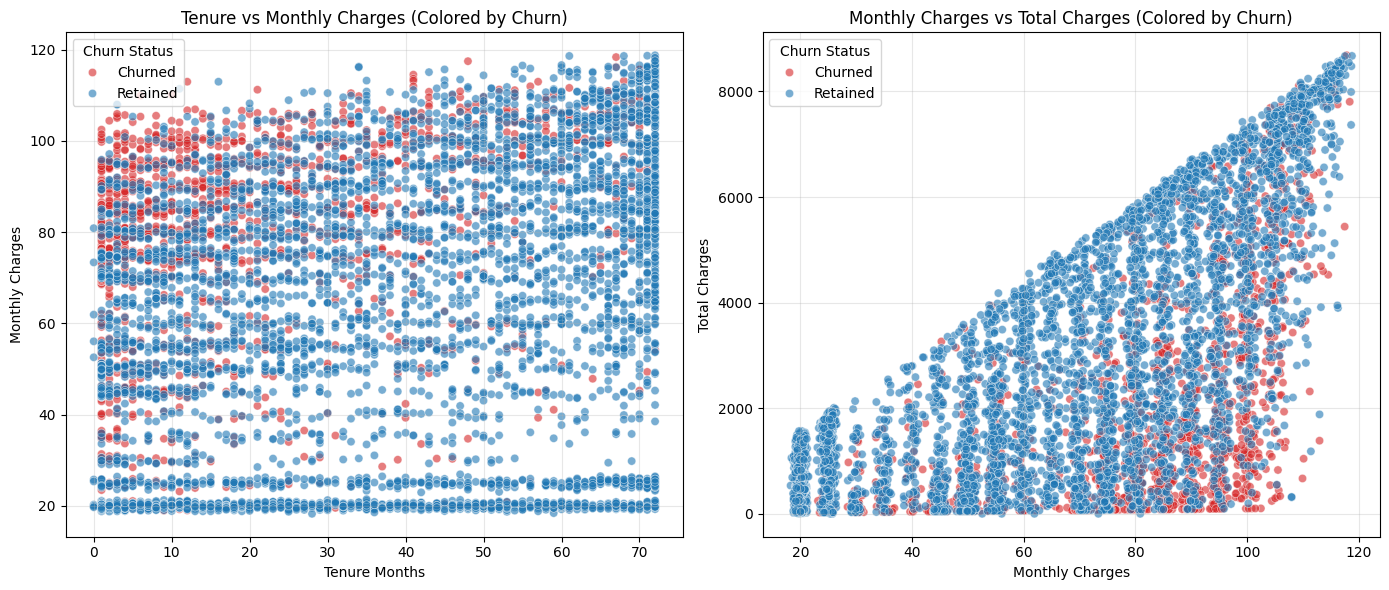

In [ ]:
# Plot a readable churn label instead of the raw 0/1 so the legend can never
# disagree with the colours: Retained = blue, Churned = red.
plot_df = df.copy()
plot_df['Churn Status'] = plot_df['Churn Value'].map({0: 'Retained', 1: 'Churned'})
churn_palette = {'Retained': 'tab:blue', 'Churned': 'tab:red'}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    x='Tenure Months', y='Monthly Charges',
    hue='Churn Status', data=plot_df, palette=churn_palette, alpha=0.6, ax=axes[0]
)
axes[0].set_title('Tenure vs Monthly Charges (Colored by Churn)')
axes[0].legend(title='Churn Status')
axes[0].grid(True, alpha=0.3)

sns.scatterplot(
    x='Monthly Charges', y='Total Charges',
    hue='Churn Status', data=plot_df, palette=churn_palette, alpha=0.6, ax=axes[1]
)
axes[1].set_title('Monthly Charges vs Total Charges (Colored by Churn)')
axes[1].legend(title='Churn Status')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Key Insights from Numeric vs Numeric Scatter Plots

1. **Churn Is a Tenure × Price Interaction — There Is No Single Boundary**
   * **Observation:** Churn appears at every tenure and every price, but the rate changes sharply by cell. Customers in months `0–12` churn at **26%** below `$40`, **43%** at `$40–70`, **67%** at `$70–90` and **75%** above `$90`; after 48 months the same price bands churn at only **2%**, **6%**, **7%** and **17%**.
   * **What It Means:** A high bill is only dangerous while the relationship is young. Neither feature alone reproduces this (r(Tenure, Churn) = -0.35, r(Monthly Charges, Churn) = +0.19), which is why univariate thresholds look weak while the two-dimensional pattern is strong.
   * **Suggested Action:** Engineer `high_bill_new_customer = (Monthly Charges > 70) & (Tenure Months < 12)` — that cell holds **826 customers with 68.6% churn**, i.e. **30.3% of all churn**, and should be one explicit segment in the model and in the retention campaign.

2. **The Total Charges Fan Is a Deterministic Wedge, Not a Cloud**
   * **Observation:** In the right plot `Total Charges` is bounded above by roughly `Monthly Charges × 72`, the points form vertical strips at each price point, and churned customers sit on the **lower rim** of the wedge (few months paid).
   * **What It Means:** The relationship is mechanical (`Total ≈ Tenure × Monthly`), so the visible pattern is tenure again; `Total Charges` adds no independent signal, and the wedge shape is why its correlation with tenure is 0.83.
   * **Suggested Action:** Use `Total Charges` as "revenue collected to date" in business reporting, but do not feed both it and tenure into linear or distance-based models.

---

### 6. Correlation Analysis - Numeric Features

Correlation matrix among numeric predictors. Helps detect multicollinearity before training Logistic Regression or SVM.


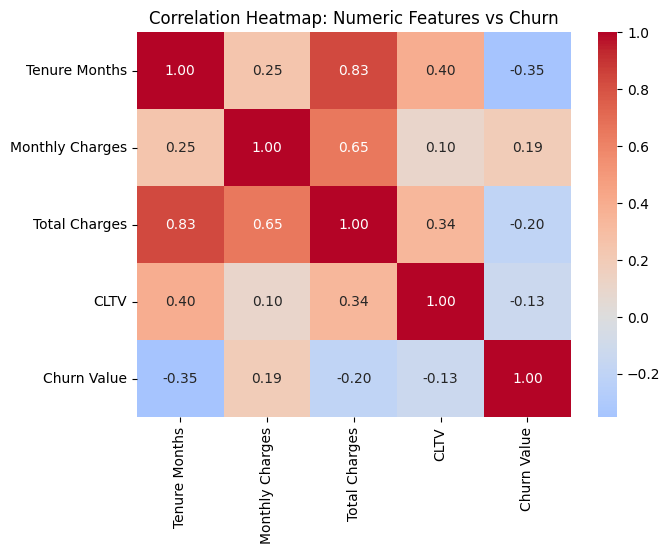

In [ ]:
corr_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV', 'Churn Value']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Heatmap: Numeric Features vs Churn')
plt.show()


### Key Insights from the Correlation Matrix

1. **Tenure Is the Strongest (Negative) Correlate of Churn**
   * **Observation:** `r(Tenure, Churn) = -0.35`, `r(Total Charges, Churn) = -0.20`, `r(Monthly Charges, Churn) = +0.19`, `r(CLTV, Churn) = -0.13`.
   * **What It Means:** The directions match every plot so far — longer tenure and higher lifetime spend lower the churn odds, higher monthly price raises them. The magnitudes are modest, so no single variable is sufficient.
   * **Suggested Action:** Rely on a multivariate model; univariate thresholds will be brittle.

2. **Strong Multicollinearity Between Tenure and Total Charges (`r = 0.83`)**
   * **Observation:** `r(Tenure, Total Charges) = 0.83`, `r(Monthly Charges, Total Charges) = 0.65`, but `r(Tenure, Monthly Charges) = 0.25`.
   * **What It Means:** `Total Charges` is nearly a linear combination of the other two. In Logistic Regression / SVM this inflates coefficients, makes them unstable and hard to interpret.
   * **Suggested Action:** For linear or distance-based models keep **either** `Total Charges` **or** (`Tenure Months`, `Monthly Charges`) — preferably the latter and drop `Total Charges`. Tree ensembles (Random Forest, XGBoost) are unaffected and can keep all three.

3. **CLTV Is Nearly Independent of the Billing Variables**
   * **Observation:** `r(CLTV, Monthly Charges) = 0.10`, `r(CLTV, Tenure) = 0.40`, `r(CLTV, Total Charges) = 0.34`.
   * **What It Means:** CLTV measures projected future value, not money already collected, so it adds a genuinely different dimension — but a weak churn predictor.
   * **Suggested Action:** Use CLTV in the expected-value formula (`P(churn) × CLTV`), not as a feature you rely on for classification.

---

### 7. Interaction Analysis - Categorical Combinations

Cross-tabulations of categorical combinations to find high-risk customer profiles. These are counts, not churn rates, and help interpret Decision Tree splits.


         Contract Internet Service  total_customers  churned_customers
1  Month-to-month      Fiber optic             2128               1162
0  Month-to-month              DSL             1223                394
4        One year      Fiber optic              539                104
2  Month-to-month               No              524                 99
3        One year              DSL              570                 53
7        Two year      Fiber optic              429                 31
6        Two year              DSL              628                 12
5        One year               No              364                  9
8        Two year               No              638                  5


/tmp/ipykernel_31200/1866603523.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


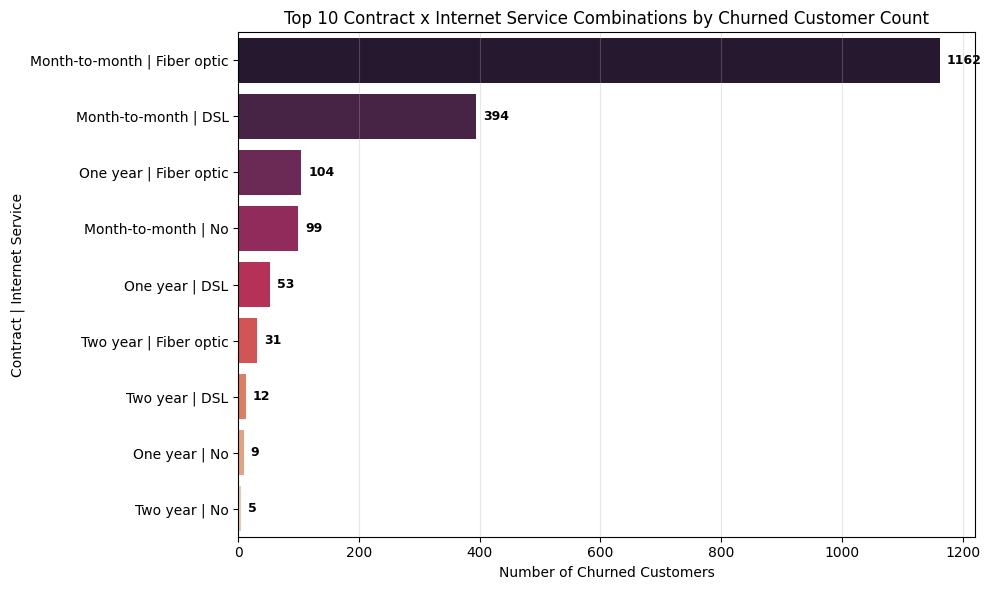

In [ ]:
combo = df.groupby(['Contract', 'Internet Service']).agg(
    total_customers=('CustomerID', 'count'),
    churned_customers=('Churn Value', 'sum')
).reset_index()
combo = combo.sort_values('churned_customers', ascending=False)

print(combo.head(10))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=combo.head(10),
    x='churned_customers',
    y=combo['Contract'] + ' | ' + combo['Internet Service'],
    palette='rocket', ax=ax
)
ax.set_title('Top 10 Contract x Internet Service Combinations by Churned Customer Count')
ax.set_xlabel('Number of Churned Customers')
ax.set_ylabel('Contract | Internet Service')
ax.grid(True, alpha=0.3, axis='x')

# Add numbers on each bar
max_val = combo['churned_customers'].head(10).max()
for i, v in enumerate(combo['churned_customers'].head(10)):
    ax.text(v + max_val * 0.01, i, f'{v}', va='center', ha='left', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


### Key Insights from Contract × Internet Service Combinations

1. **One Segment Produces Most of the Churn**
   * **Observation:** **Month-to-month + Fiber optic = 2,128 customers, 1,162 churned (54.6%)** — that single combination accounts for **62.2%** of all **1,869** churned customers.
   * **What It Means:** Churn is not spread evenly; it is concentrated in the no-contract, premium-product segment. Aggregate churn rates hide this concentration, which makes generic retention offers look ineffective.
   * **Suggested Action:** Make month-to-month fiber the primary campaign target (contract upgrade plus a fiber quality / price review) instead of applying one global offer.

2. **There Is a Clear Safety Gradient by Contract Length**
   * **Observation:** Churn rate per combination (MTM = month-to-month): MTM + Fiber **54.6%**, MTM + DSL **32.2%**, One year + Fiber **19.3%**, MTM + No internet **18.9%**, One year + DSL **9.3%**, Two year + Fiber **7.2%**, One year + No internet **2.5%**, Two year + DSL **1.9%**, Two year + No internet **0.8%**.
   * **What It Means:** Contract length dominates internet type — each step up in commitment cuts churn to roughly a third (fiber: **54.6% → 19.3% → 7.2%**) and even lower for DSL / no-internet customers, while fiber only adds risk inside the month-to-month group. Note the chart shows *counts*, so the biggest bar is partly a size effect, not only a risk effect.
   * **Suggested Action:** Sell commitment first (annual plan), then product quality, and measure campaign success by the churn-rate drop inside this 3×3 grid rather than by total churn count.

---

### 8. Churn Reasons Deep Dive

Most common churn reasons among customers who already churned.


/tmp/ipykernel_31200/1989377295.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_reasons.values, y=top_reasons.index, palette='rocket')


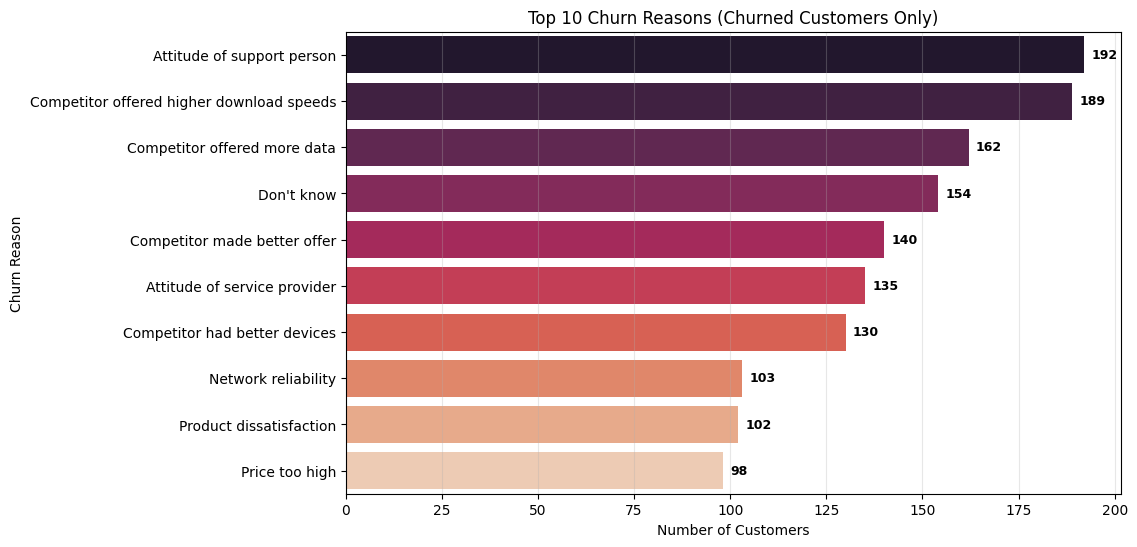

In [ ]:
churned = df[df['Churn Value'] == 1]
top_reasons = churned['Churn Reason'].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_reasons.values, y=top_reasons.index, palette='rocket')
plt.title('Top 10 Churn Reasons (Churned Customers Only)')
plt.xlabel('Number of Customers')
plt.ylabel('Churn Reason')
plt.grid(True, alpha=0.3, axis='x')

# Add numbers on each bar
max_val = top_reasons.max()
for i, v in enumerate(top_reasons.values):
    plt.text(v + max_val * 0.01, i, f'{v}', va='center', ha='left', fontsize=9, fontweight='bold')

plt.show()


### Key Insights from Churn Reasons

1. **Competition — Not Price — Is the Main Reason**
   * **Observation:** Of the **1,869** churned customers, **621 (33.2%)** named a competitor: higher download speeds (**189, 10.1%**), more data (**162, 8.7%**), a better offer (**140, 7.5%**), better devices (**130, 7.0%**). "Price too high" is only **98 (5.2%)**.
   * **What It Means:** Customers are not mainly leaving because the bill is high; they leave because a competitor looks better on product, speed and hardware value. Discounts alone will not fix that.
   * **Suggested Action:** Compete on speed, data allowances and device refresh rather than price cuts — the fiber speed gap is the single largest named reason.

2. **Support and Service Experience Is the Second Biggest Theme**
   * **Observation:** "Attitude of support person" (**192, 10.3%**) is the #1 individual reason, plus "attitude of service provider" (**135, 7.2%**) — **327 (17.5%)** cite staff attitude. Service dissatisfaction (89), lack of self-service on the website (88) and poor expertise of phone / online support (20 + 19) add another **11.6%**.
   * **What It Means:** About **29%** of churn is explained by how the customer was treated or how hard it was to get help — the cheapest theme to fix, and unrelated to network investment.
   * **Suggested Action:** Prioritise agent training and self-service tooling, and combine it with the month 1–12 retention window where most churn occurs.

3. **A Long Tail of Operational Friction, Plus Noise**
   * **Observation:** Network reliability (**103, 5.5%**), product dissatisfaction (**102, 5.5%**), extra data charges (**57, 3.0%**), long distance charges (**44, 2.4%**), limited range of services (**44**), lack of affordable speed (**44**), moved (**53, 2.8%**), deceased (**6**). Separately, **154 (8.2%)** answered "Don't know".
   * **What It Means:** Surprise line items (extra data, long distance) are self-inflicted churn that can be designed out, while "moved" and "deceased" are unavoidable and should be excluded from retention targeting. The "Don't know" block shows that self-reported reasons are noisy and should be read as directional.
   * **Suggested Action:** Remove surprise charges with unlimited data / long-distance add-ons, track network reliability by region, and exclude moved / deceased / "don't know" from reason-based modelling.

---

## Data Preprocessing (Feature Engineering, Encoding & Scaling)

### 1. Drop Columns

In [ ]:
df_model = df.copy()

drop_cols = [
    'CustomerID',
    'Count', 'Country', 'State',
    'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude',
    'Gender',
    'Churn Label',
    'Churn Score', 'Churn Reason',
]
df_model = df_model.drop(columns=drop_cols)
print(df_model.shape)

(7043, 20)


### 2. Feature Engineering

In [ ]:
service_cols = ['Online Security', 'Online Backup', 'Device Protection',
                'Tech Support', 'Streaming TV', 'Streaming Movies']

df_model['Num Services'] = (df_model[service_cols] == 'Yes').sum(axis=1)

df_model['Tenure Group'] = pd.cut(df_model['Tenure Months'],
                                  bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)

df_model['Has Family'] = ((df_model['Partner'] == 'Yes') | (df_model['Dependents'] == 'Yes')).astype(int)

df_model['Auto Pay'] = df_model['Payment Method'].isin(
    ['Bank transfer (automatic)', 'Credit card (automatic)']).astype(int)

df_model[['Num Services', 'Tenure Group', 'Has Family', 'Auto Pay']].head()

,Num Services,Tenure Group,Has Family,Auto Pay
0,2,0-12,0,0
1,0,0-12,1,0
2,3,0-12,1,0
3,4,25-48,1,0
4,4,49-72,1,1


In [ ]:
for col in ['Num Services', 'Tenure Group', 'Has Family', 'Auto Pay']:
    print(df_model.groupby(col)['Churn Value'].mean().round(3), '\n')

Num Services
0    0.214
1    0.458
2    0.358
3    0.274
4    0.223
5    0.124
6    0.053
Name: Churn Value, dtype: float64 

Tenure Group
0-12     0.474
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn Value, dtype: float64 

Has Family
0    0.344
1    0.194
Name: Churn Value, dtype: float64 

Auto Pay
0    0.347
1    0.160
Name: Churn Value, dtype: float64 



### 3. Encoding

In [ ]:
yes_no_cols = ['Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines',
               'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
               'Streaming TV', 'Streaming Movies', 'Paperless Billing']

for col in yes_no_cols:
    df_model[col] = (df_model[col] == 'Yes').astype(int)

one_hot_cols = ['Contract', 'Internet Service', 'Payment Method', 'Tenure Group']
df_model = pd.get_dummies(df_model, columns=one_hot_cols, drop_first=True, dtype=int)

print(df_model.shape)
print(df_model.dtypes.value_counts())
df_model.head()

(7043, 30)
int64      28
float64     2
Name: count, dtype: int64


,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,Tech Support,...,Contract_One year,Contract_Two year,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check,Tenure Group_13-24,Tenure Group_25-48,Tenure Group_49-72
0,0,0,0,2,1,0,1,1,0,0,...,0,0,0,0,0,0,1,0,0,0
1,0,0,1,2,1,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0
2,0,0,1,8,1,1,0,0,1,0,...,0,0,1,0,0,1,0,0,0,0
3,0,1,1,28,1,1,0,0,1,1,...,0,0,1,0,0,1,0,0,1,0
4,0,0,1,49,1,1,0,1,1,0,...,0,0,1,0,0,0,0,0,0,1


### 4. Train / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['Churn Value'])
y = df_model['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Churn rate train:', round(y_train.mean(), 3), '| test:', round(y_test.mean(), 3))

Train: (5634, 29) | Test: (1409, 29)
Churn rate train: 0.265 | test: 0.265


### 5. Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV', 'Num Services']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

X_train_scaled[scale_cols].describe().round(2).loc[['mean', 'std']]

,Tenure Months,Monthly Charges,Total Charges,CLTV,Num Services
mean,-0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


### 6. Class Imbalance Check

In [ ]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

Churn Value
0    4139
1    1495
Name: count, dtype: int64
Churn Value
0    0.735
1    0.265
Name: proportion, dtype: float64


### 7. Final Check & Save

In [ ]:
print('Missing values:', X_train_scaled.isnull().sum().sum(), X_test_scaled.isnull().sum().sum())
print('Non-numeric columns:', list(X_train_scaled.select_dtypes(exclude='number').columns))
print('Number of features:', X_train_scaled.shape[1])

X_train_scaled.assign(Churn=y_train.values).to_csv('train_preprocessed.csv', index=False)
X_test_scaled.assign(Churn=y_test.values).to_csv('test_preprocessed.csv', index=False)
print('Saved train_preprocessed.csv and test_preprocessed.csv')

import joblib
joblib.dump(scaler, 'scaler.pkl')

Missing values: 0 0
Non-numeric columns: []
Number of features: 29
Saved train_preprocessed.csv and test_preprocessed.csv


['scaler.pkl']

### Preprocessing Summary

| Step | What we did | Why |
|---|---|---|
| Drop columns | ID, constant, location, Gender, Churn Label/Score/Reason | no signal, or leak the answer |
| Feature engineering | Num Services, Tenure Group, Has Family, Auto Pay | capture patterns found in the EDA |
| Encoding | Yes/No -> 1/0, one-hot for Contract, Internet, Payment, Tenure Group | models need numbers |
| Split | 80% train / 20% test, stratified | keep the churn ratio equal |
| Scaling | StandardScaler on 5 numeric columns (fit on train only) | helps Logistic Regression / SVM; avoids leakage |
| Imbalance | kept as is; use class_weight='balanced' when training | only ~26.5% churn |

---

Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
#base decsion tree model
base = DecisionTreeClassifier(random_state=42).fit(X_train_scaled, y_train)
print(f"train={base.score(X_train_scaled, y_train)} " f"test={base.score(X_test_scaled, y_test)}")
#Overfitting

train=1.0 test=0.7345635202271115


In [ ]:
#pre-pruned decision tree model
param_grid = {
    "max_depth": [2, 3, 4, 5, 7, 10, 12, 15, None],
    "min_samples_leaf": [1, 3, 5, 10, 15, 20,],
    "min_samples_split": [2, 5, 10, 20],
    "criterion": ["gini", "entropy"],
}

grid = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5).fit(X_train_scaled, y_train)

print("Grid best parameters: ", grid.best_params_)

y_pred_pre = grid.predict(X_test_scaled)
y_proba_pre = grid.predict_proba(X_test_scaled)[:, 1]

Grid best parameters:  {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 20, 'min_samples_split': 2}


In [ ]:
print(f"Score : train={grid.score(X_train_scaled, y_train): }  " f"test={grid.score(X_test_scaled, y_test): }\n")
print(confusion_matrix(y_test, y_pred_pre))
print(classification_report(y_test, y_pred_pre))

auc_pre = roc_auc_score(y_test, y_proba_pre)
print(f"ROC AUC: {auc_pre}")

Score : train= 0.8168264110756124  test= 0.7856635911994322

[[889 146]
 [156 218]]
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.60      0.58      0.59       374

    accuracy                           0.79      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.79      0.78      1409

ROC AUC: 0.8297385620915032


In [ ]:
#post-pruned decision tree model
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train_scaled, y_train)
ccp_alphas = path.ccp_alphas[:-1]

#choose the alpha with the best cross-validation score
cv_scores = [cross_val_score(DecisionTreeClassifier(random_state=42, ccp_alpha=a), X_train_scaled, y_train, cv=5).mean() for a in ccp_alphas]
best_alpha = ccp_alphas[np.argmax(cv_scores)]

post_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
post_pruned.fit(X_train_scaled, y_train)

print(f"best_alpha={best_alpha}  depth={post_pruned.get_depth()}  "f"leaves={post_pruned.get_n_leaves()}")

y_pred_post = post_pruned.predict(X_test_scaled)
y_proba_post = post_pruned.predict_proba(X_test_scaled)[:, 1]

best_alpha=0.0009254189669241093  depth=6  leaves=20


In [ ]:
print(f"Score : train={post_pruned.score(X_train_scaled, y_train): }  "f"test={post_pruned.score(X_test_scaled, y_test): }\n")
print(confusion_matrix(y_test, y_pred_post))
print(classification_report(y_test, y_pred_post))

auc_post = roc_auc_score(y_test, y_proba_post)
print(f"ROC AUC: {auc_post}")

Score : train= 0.806354277600284  test= 0.7970191625266146

[[888 147]
 [139 235]]
              precision    recall  f1-score   support

           0       0.86      0.86      0.86      1035
           1       0.62      0.63      0.62       374

    accuracy                           0.80      1409
   macro avg       0.74      0.74      0.74      1409
weighted avg       0.80      0.80      0.80      1409

ROC AUC: 0.8285799168152108


Random Forest

In [ ]:
rf_param_search = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 8, 12, 15],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", "log2", None],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_search,
    n_iter=10,
    cv=3,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train_scaled, y_train)

RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_jobs=-1,
                   param_distributions={'max_depth': [None, 8, 12, 15],
                                        'max_features': ['sqrt', 'log2', None],
                                        'min_samples_leaf': [1, 3, 5],
                                        'n_estimators': [100, 200, 300]},
                   random_state=42)

In [ ]:
print("Best params:", rf_search.best_params_)
print("Best CV accuracy:", rf_search.best_score_)

best_rf = rf_search.best_estimator_
y_pred_rf = best_rf.predict(X_test_scaled)
print(f"\nScore : train={best_rf.score(X_train_scaled, y_train)}  "f"test={best_rf.score(X_test_scaled, y_test)}\n")
print(classification_report(y_test, y_pred_rf))

y_proba_rf = best_rf.predict_proba(X_test_scaled)[:, 1]

auc_rf = roc_auc_score(y_test, y_proba_rf)
print(f"ROC AUC: {auc_rf}")

Best params: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 'log2', 'max_depth': 12}
Best CV accuracy: 0.807596734114306

Score : train=0.8791267305644302  test=0.8069552874378992

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.67      0.54      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC AUC: 0.8521028701335607
